In [118]:
### Libaries - Joe
from smo import K1,K2,evalSMO, smo, plotSMO #compiled python from ipynb from assignment 5 code
import pandas as pd
import numpy as np
import copy
import time
import matplotlib.pyplot as plt 
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [119]:
### Random Seed & Other Constants - Joe
RANDOM_SEED = 0
EPS = 10**-8
TAU = 10**-3
MAX_ITER = 10**4

# Problem 1 — Backpropagation for a 2–H–1 network- Joe

### A - Implementation and tests - Joe

In [120]:
### Sigmoid activation function from previous hw - Joe
def sigmoid(z):
    # no overflow warning for z=abs(1000)
    # clip to abs(500), beyond that call np.exp()
    z = np.clip(z, -500,500)
    return 1 / (1 + np.exp(-z))

In [121]:
### Define a class to abstract the weights and biases of the mlp - Joe
class MLP_W:
    def __init__(self):
        # Weights and biases to be init later
        self.Hidden_Weights = None
        self.Hidden_Bias = None
        self.Output_Weights = None
        self.Output_Bias = None

        # alpha momentum for weights as suggested in slide 67
        self.Hidden_W_Alpha = None
        self.Hidden_B_Alpha = None
        self.Output_W_Alpha = None
        self.Output_B_Alpha = None

In [122]:
### Similar to SMO approach - helper function to init MLP - Joe
def initMLP(H, RNG):
    W = MLP_W()
    W.Hidden_Weights = RNG.uniform(-0.5, 0.5,size=(2,H)) # two inputs
    W.Hidden_Bias =RNG.uniform(-0.5, 0.5,size=(1,H))
    W.Output_Weights = RNG.uniform(-0.5, 0.5,size=(H,1)) # one output
    W.Output_Bias =RNG.uniform(-0.5, 0.5,size=(1,1))

    W.Hidden_W_Alpha = np.zeros_like(W.Hidden_Weights)
    W.Hidden_B_Alpha = np.zeros_like(W.Hidden_Bias)
    W.Output_W_Alpha = np.zeros_like(W.Output_Weights)
    W.Output_B_Alpha = np.zeros_like(W.Output_Bias)
    return W

In [123]:
### Implement forward - calculate hidden&output activation terms for each neuron - Joe
def forward(X,W):
    hidden = sigmoid(X @ W.Hidden_Weights + W.Hidden_Bias)
    output = sigmoid(hidden @ W.Output_Weights + W.Output_Bias)
    return output,hidden

In [124]:
### Implement backward - calculates output&hidden error terms for each neuron - Joe
def backward(W, output,hidden,t):
    # taking from delta_o = o(1-o)(t-o), 
    # where t= 0.9 if y=+1 then 0.1 otherwise y=-1
    delta_o = output * (1-output)* (t-output)
    # hidden 
    delta_h = hidden * (1-hidden) *(delta_o @ W.Output_Weights.T)
    return delta_o, delta_h

In [125]:
### Implement - update weights by computing deltas for each neuron - Joe
def updateWeights(X,W, hidden, delta_o, delta_h, eta,alpha):
    # use momentum and calculate deltas
    delta_Output_Weights = eta*(hidden.T @ delta_o) +alpha*W.Output_W_Alpha
    delta_Output_Bias = eta * delta_o + alpha * W.Output_B_Alpha

    delta_Hidden_Weights = eta * (X.T @ delta_h) + alpha * W.Hidden_W_Alpha
    delta_Hidden_Bias = eta * delta_h + alpha * W.Hidden_B_Alpha

    # apply updates
    W.Output_Weights += delta_Output_Weights
    W.Output_Bias += delta_Output_Bias
    W.Hidden_Weights += delta_Hidden_Weights
    W.Hidden_Bias += delta_Hidden_Bias

    # save momentum
    W.Output_W_Alpha = delta_Output_Weights
    W.Output_B_Alpha = delta_Output_Bias
    W.Hidden_W_Alpha = delta_Hidden_Weights
    W.Hidden_B_Alpha = delta_Hidden_Bias
    
    return W

In [126]:
### Implement mlp_train - Joe
# in hw description it does not have the Xte, yte parameters, but is needed for 
# problem 1b
# same for validation
def mlp_train(X,y,H,eta=0.3,alpha=0.3,epochs=1000,seed=RANDOM_SEED, Xte=None, yte=None, Xval=None, yval=None):
    #https://numpy.org/doc/stable/reference/random/generator.htmlNe
    # initialize multilayer perceptron
    RNG = np.random.default_rng(seed)
    W = initMLP(H, RNG)

    # target for this assignment is 0.9
    targets = np.where(y==1, 0.9,0.1)
    epochMonitor = {
        "weights": [],
        "errs" : [],
        "miscs" : [],
        "testMiscs": [],
        "testErrs": [],
        "valMiscs": [],
        "valErrs": []
    }

    # training loop
    for epoch in range(epochs):

        # shuffle training examples
        idxs = RNG.permutation(len(X))

        # stochastic updates
        for i in idxs:
            # obtain example and label
            ex = X[i:i+1] # for shape (1,2)
            t = targets[i]

            # update mlp
            output, hidden = forward(ex, W)
            delta_o,delta_h = backward(W, output, hidden, t)
            W = updateWeights(ex, W, hidden, delta_o, delta_h, eta, alpha)

        # evaluate for epoch monitor
        outputs, hiddens = forward(X,W)
        outputs = outputs.ravel()

        # mse Ed[⃗w] ≡ 1/2(td − od)2
        err = 0.5*np.mean((targets -outputs)**2)

        # miscs as a rate
        preds = np.where(outputs >0.5,1,-1)
        misc = np.mean(preds !=y)

        epochMonitor["errs"].append(err)
        epochMonitor["miscs"].append(misc)
        epochMonitor["weights"].append(copy.deepcopy(W)) # https://docs.python.org/3/library/copy.html preserves W so can't be changed later

        # optional monitoring for subparts
        if Xte is not None and yte is not None:
            testOutputs,_ = forward(Xte,W)
            testOutputs = testOutputs.ravel()

            # miscs and then errs
            testPreds =  np.where(testOutputs >0.5,1,-1)
            testTargets = np.where(yte == 1, 0.9, 0.1)
            testMiscs = np.mean(testPreds!=yte)
            testErr = 0.5*np.mean((testTargets -testOutputs)**2)
            epochMonitor["testMiscs"].append(testMiscs)
            epochMonitor["testErrs"].append(testErr)
        if Xval is not None and yval is not None:
            valOutputs,_ = forward(Xval,W)
            valOutputs = valOutputs.ravel()

            # miscs and then errs
            valPreds =  np.where(valOutputs >0.5,1,-1)
            valsTargets = np.where(yval == 1, 0.9, 0.1)
            valMiscs = np.mean(valPreds!=yval)
            valErr = 0.5*np.mean((valsTargets -valOutputs)**2)
            epochMonitor["valMiscs"].append(valMiscs)
            epochMonitor["valErrs"].append(valErr)
    return W, epochMonitor

In [127]:
### 1 - Reproduce worked example - Joe
W = MLP_W()

# hidden neurons
W.Hidden_Weights = np.asarray([
    [0.4,0.2],
    [-0.2,0.5]
])
W.Hidden_Bias = np.asarray([
    [0.1, -0.3]
])

# output neuron
W.Output_Weights = np.asarray([
    [0.6],
    [-0.4]
])
W.Output_Bias = np.array([
    [0.2]
])

# momentum
W.Hidden_W_Alpha = np.zeros_like(W.Hidden_Weights)
W.Hidden_B_Alpha = np.zeros_like(W.Hidden_Bias)
W.Output_W_Alpha = np.zeros_like(W.Output_Weights)
W.Output_B_Alpha = np.zeros_like(W.Output_Bias)

# inits
X = np.array([
    [1.0,0.0]
])
t= 1.0
eta=0.5
alpha=0.0 #no momentum

# perform update
outputBefore, hidden = forward(X,W)
delta_o,delta_h = backward(W,outputBefore,hidden,t)
W = updateWeights(X,W,hidden,delta_o,delta_h,eta,alpha)


# get weights
outputAfter,_ = forward(X,W)

print("Weights before update: {:.4f}".format(outputBefore.item())) #item is used to access the value
print("Weights after update: {:.4f}".format(outputAfter.item())) 

Weights before update: 0.5947
Weights after update: 0.6142


In [128]:
### helper function to compute error
def computeErr(X,W,t):
    output,_ = forward(X,W)
    return 0.5*(t - output.item())**2

In [129]:
### 2 - Gradient Check - Joe
gradEps = 10**-5
rng = np.random.default_rng(seed=0)
W = initMLP(4, rng)

# randomly init a observation
X = rng.normal(size=(1,2))
t = 0.9

# update
output, hidden = forward(X, W)
delta_o, delta_h = backward(W, output, hidden, t)

# gradient checks
HiddenWeightsChk = -(X.T @ delta_h)
HiddenBiasChk = -delta_h
OutputWeightsChk = -(hidden.T @ delta_o)
OutputBiasChk = -delta_o

# to check greatest difference in errs
maxDiff = 0.0

# check hidden weights err
for ind in np.ndindex(HiddenWeightsChk.shape):
    original = W.Hidden_Weights[ind]

    # perform calculated
    W.Hidden_Weights[ind] = original + gradEps
    first = computeErr(X, W, t)
    W.Hidden_Weights[ind] = original - gradEps
    second = computeErr(X, W, t)

    # get back original
    W.Hidden_Weights[ind] = original

    # compute calcErr and check difference
    calcErr = (first - second) / (2 * gradEps)
    trueErr = HiddenWeightsChk[ind]
    diff = abs(trueErr-calcErr)/max(10**-9,abs(trueErr)+abs(calcErr)) #10**-9 avoid div0
    maxDiff = max(maxDiff, diff)


# check hidden bias err
for ind in np.ndindex(HiddenBiasChk.shape):
    original = W.Hidden_Bias[ind]

    # perform calculated
    W.Hidden_Bias[ind] = original + gradEps
    first = computeErr(X, W, t)
    W.Hidden_Bias[ind] = original - gradEps
    second = computeErr(X, W, t)

    # get back original
    W.Hidden_Bias[ind] = original

    # compute calcErr and check difference
    calcErr = (first - second)/ (2 * gradEps)
    trueErr = HiddenBiasChk[ind]
    diff = abs(trueErr-calcErr)/max(10**-9,abs(trueErr)+abs(calcErr))
    maxDiff = max(maxDiff, diff)

# check output weights err
for ind in np.ndindex(OutputWeightsChk.shape):
    original = W.Output_Weights[ind]

    # perform calcualted
    W.Output_Weights[ind] = original + gradEps
    first = computeErr(X, W, t)
    W.Output_Weights[ind] = original - gradEps
    second = computeErr(X, W, t)

    # get back original
    W.Output_Weights[ind] = original

    # compute calcErr and check difference
    calcErr = (first - second) / (2 * gradEps)
    trueErr = OutputWeightsChk[ind]
    diff = abs(trueErr-calcErr)/max(10**-9,abs(trueErr)+abs(calcErr))
    maxDiff = max(maxDiff, diff)


# check output bias err
for ind in np.ndindex(OutputBiasChk.shape):
    original = W.Output_Bias[ind]

    # perform calculated
    W.Output_Bias[ind] = original + gradEps
    first = computeErr(X, W, t)
    W.Output_Bias[ind] = original - gradEps
    second = computeErr(X, W, t)

    # get back original
    W.Output_Bias[ind] = original

    # compute calcErr and check difference
    calcErr = (first-second)/(2* gradEps)
    trueErr = OutputBiasChk[ind]
    diff = abs(trueErr-calcErr)/max(10**-9,abs(trueErr)+abs(calcErr))
    maxDiff = max(maxDiff, diff)


print("Largest Relative Difference: {:.3e}".format(maxDiff)) #scientific notation
print("Is Gradient Check Passed: {}".format(maxDiff < 10**-6))

Largest Relative Difference: 3.629e-10
Is Gradient Check Passed: True


### B - Capacity and Local Minima on Data Set 2 (XOR) - Joe

In [130]:
### Helper standardize from previous hw - Joe
def standardize(Xtr, Xte):
    """Mean/std from the TRAINING set only, applied to both sets."""
    mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
    sd[sd == 0] = 1 #prevent div0
    return (Xtr - mu) / sd, (Xte - mu) / sd, mu, sd

In [131]:
### Helper stratified split from previous hw - Joe
def stratified_split(X, y,test_fraction=0.2, seed=RANDOM_SEED):
    """Seeded, class-proportional train/test split."""
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for k in np.unique(y):
        idx_k = np.where(y == k)[0]
        rng.shuffle(idx_k)
        n_test_k = int(round(len(idx_k) * test_fraction))
        test_idx.extend(idx_k[:n_test_k])
        train_idx.extend(idx_k[n_test_k:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

In [132]:
### Data set 2 - XOR - Joe
d2trainDF = pd.read_csv("data/xor_train.csv")
d2testDF = pd.read_csv("data/xor_test.csv")

# split into train and test
d2Xtr = d2trainDF[["x1","x2"]].values
d2Xte = d2testDF[["x1","x2"]].values
d2ytr = d2trainDF["y"].values
d2yte = d2testDF["y"].values

# standardize
d2Xtr,d2Xte = standardize(d2Xtr, d2Xte)[:2]

# collect statistics
d2Hlabels = []
d2Hmonitors = []
d2Hweights = []

# sweep h
Hs = [2,4,8,16]
for H in Hs:   
    W, monitor = mlp_train(d2Xtr,d2ytr,H,epochs=1000, Xte=d2Xte, yte=d2yte)

    # preds on test
    outputs,_ = forward(d2Xte,W)
    preds = np.where(outputs.ravel()>0.5,1,-1)

    # update
    d2Hlabels.append(preds)
    d2Hmonitors.append(monitor)
    d2Hweights.append(W)


Confusion Matrix for H = 2
[[43  4]
 [ 2 51]]
Confusion Matrix for H = 4
[[47  0]
 [ 0 53]]
Confusion Matrix for H = 8
[[47  0]
 [ 0 53]]
Confusion Matrix for H = 16
[[47  0]
 [ 0 53]]


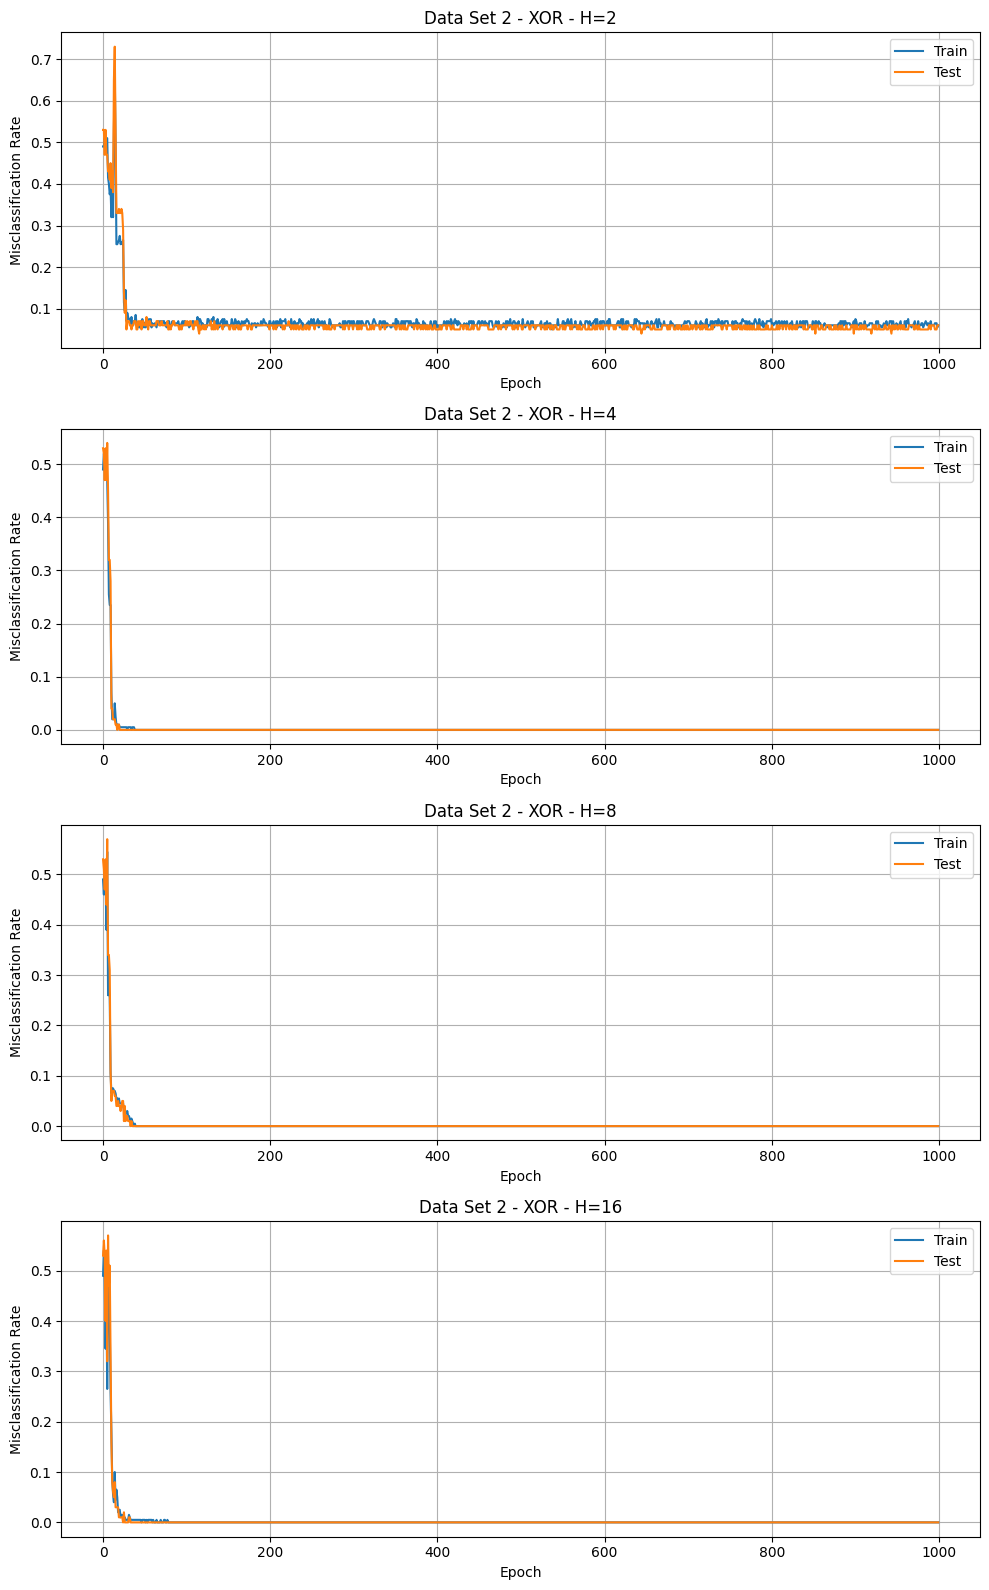

In [133]:
### 1 - Plot training and test miscs rates and give test confusion matrix - Joe
# we have 4 different h's show all on separate suplots, with confusion matrix,
fig,ax = plt.subplots(nrows=4, ncols=1, figsize=(10,16))
for i, H in enumerate(Hs):
    monitor = d2Hmonitors[i]

    print("Confusion Matrix for H = {}".format(H))
    print(confusion_matrix(d2yte, d2Hlabels[i]))
    ax[i].plot(monitor["miscs"], label="Train")
    ax[i].plot(monitor["testMiscs"], label="Test")

    ax[i].set_title(f"Data Set 2 - XOR - H={H}")
    ax[i].set_xlabel("Epoch")
    ax[i].set_ylabel("Misclassification Rate")
    ax[i].legend()
    ax[i].grid()

plt.tight_layout()
plt.show()

In [134]:
### 2 - Repeat H=2 with 5 different seeds and report 95%... - Joe
# collect statistics
d2Hlabels = []
seeds = [0,1,2,3,4]
for seed in seeds:
    W, monitor = mlp_train(d2Xtr,d2ytr,2,epochs=1000, seed=seed)
    
    # preds on test
    outputs,_ = forward(d2Xte,W)
    preds = np.where(outputs.ravel()>0.5,1,-1)

    # update
    d2Hlabels.append(preds)

In [135]:
### report runs with acc over 95% - Joe
num = 0
for i in range(5):
    acc = accuracy_score(d2yte, d2Hlabels[i])
    print(f"Run {i+1} acc: {acc}")
    if  acc>= 0.95:
        num+=1
print("{} Runs out of 5 different seeds reached 95% test accuracy.".format(num))

Run 1 acc: 0.94
Run 2 acc: 0.94
Run 3 acc: 0.74
Run 4 acc: 0.93
Run 5 acc: 0.95
1 Runs out of 5 different seeds reached 95% test accuracy.


### C - Overfitting and early stopping on data set 4 - Joe

In [136]:
### Data set 4 - iris_versicolor_virginica - Joe
dataDF = pd.read_csv("data/iris_versicolor_virginica.csv")

d4X = dataDF[["petal_length", "petal_width"]].values
d4y = dataDF["y"].values

# 60/20/20
d4Xtr, d4Xte, d4ytr, d4yte = stratified_split(d4X, d4y, test_fraction=1/5)
d4Xtr, d4Xval, d4ytr, d4yval = stratified_split(d4Xtr, d4ytr, test_fraction=1/4)

# standardize
d4mu = d4Xtr.mean(axis=0)
d4std = d4Xtr.std(axis=0)
d4std[d4std == 0] = 1

d4Xtr = (d4Xtr - d4mu) / d4std
d4Xval = (d4Xval - d4mu) / d4std
d4Xte = (d4Xte - d4mu) / d4std

print(len(d4Xtr), len(d4Xval), len(d4Xte))
d4W, d4monitor = mlp_train(d4Xtr, d4ytr, 16,epochs=3000, Xte=d4Xte, yte=d4yte, Xval=d4Xval, yval=d4yval)

60 20 20


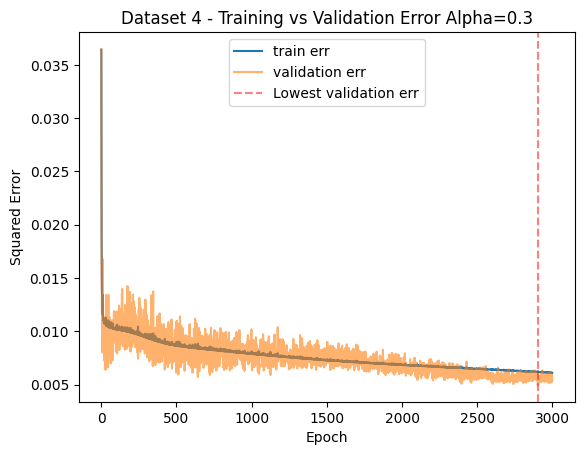

In [137]:
### 1 - Plot both curves, mark lowest val err - Joe
lowEpoch = np.argmin(d4monitor["valErrs"])
fig, ax = plt.subplots()
ax.plot(d4monitor["errs"],label="train err")
ax.plot(d4monitor["valErrs"], alpha=0.6,label="validation err")
ax.axvline(lowEpoch, color="red", linestyle="--", alpha=0.5, label="Lowest validation err")
plt.legend()
ax.set_xlabel("Epoch")
ax.set_ylabel("Squared Error")
ax.set_title("Dataset 4 - Training vs Validation Error Alpha=0.3")
plt.show()

In [138]:
### Data set 4 - iris_versicolor_virginica - optional with high alpha - Joe
dataDF = pd.read_csv("data/iris_versicolor_virginica.csv")

opd4X = dataDF[["petal_length", "petal_width"]].values
opd4y = dataDF["y"].values

# 60/20/20
opd4Xtr, opd4Xte, opd4ytr, opd4yte = stratified_split(opd4X, opd4y, test_fraction=1/5)
opd4Xtr, opd4Xval, opd4ytr, opd4yval = stratified_split(opd4Xtr, opd4ytr, test_fraction=1/4)

# standardize
opd4mu = opd4Xtr.mean(axis=0)
opd4std = opd4Xtr.std(axis=0)
opd4std[opd4std == 0] = 1

opd4Xtr = (opd4Xtr - opd4mu) / opd4std
opd4Xval = (opd4Xval - opd4mu) / opd4std
opd4Xte = (opd4Xte - opd4mu) / opd4std

print(len(opd4Xtr), len(opd4Xval), len(opd4Xte))
opd4W, opd4monitor = mlp_train(opd4Xtr, opd4ytr, 16,alpha=0.9,epochs=3000, Xte=opd4Xte, yte=opd4yte, Xval=opd4Xval, yval=opd4yval)

60 20 20


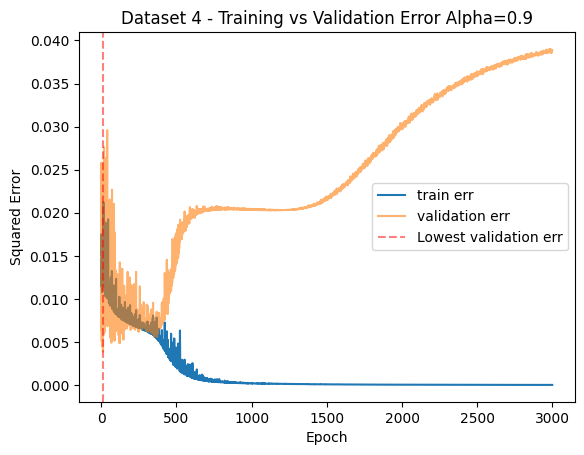

In [139]:
### 1 - Plot both curves, mark lowest val err - optional with high alpha - Joe
oplowEpoch = np.argmin(opd4monitor["valErrs"])
fig, ax = plt.subplots()
ax.plot(opd4monitor["errs"],label="train err")
ax.plot(opd4monitor["valErrs"], alpha=0.6,label="validation err")
ax.axvline(oplowEpoch, color="red", linestyle="--", alpha=0.5, label="Lowest validation err")
plt.legend()
ax.set_xlabel("Epoch")
ax.set_ylabel("Squared Error")
ax.set_title("Dataset 4 - Training vs Validation Error Alpha=0.9")
plt.show()

In [140]:
### 2 - Report test acc and test confmat - Joe
lowEpochW = d4monitor["weights"][lowEpoch]
lowOutputs,_ = forward(d4Xte,lowEpochW)
lowPreds = np.where(lowOutputs.ravel()>0.5,1,-1)
outputs,_ = forward(d4Xte,d4W)
preds = np.where(outputs.ravel()>0.5,1,-1)

# test accs
print("Test Accuracy for the low epoch #{} : {:.4f}".format(lowEpoch, accuracy_score(d4yte,lowPreds)))
print("Test Accuracy for the final epoch: {:.4f}".format(accuracy_score(d4yte,preds)))

# confusion mats
print("Confusion Matrix for the low epoch #{}".format(lowEpoch+1))
print(confusion_matrix(d4yte, lowPreds))
print("Confusion Matrix for the final epoch")
print(confusion_matrix(d4yte, preds))

Test Accuracy for the low epoch #2903 : 0.9000
Test Accuracy for the final epoch: 0.9000
Confusion Matrix for the low epoch #2904
[[10  0]
 [ 2  8]]
Confusion Matrix for the final epoch
[[10  0]
 [ 2  8]]


# Problem 2 - Decision Surfaces: MLP vs. SMO

### A - Plot Decision Surfaces for data sets 1-3 - Joe

In [141]:
### Data set 1 - Iris,Setosa vs Versicolor - Joe
d1trainDF = pd.read_csv("data/iris_setosa_versicolor_train.csv")
d1testDF = pd.read_csv("data/iris_setosa_versicolor_test.csv")

# split into train and test, convert to numpy for mlp
d1Xtr = d1trainDF[["sepal_length","petal_length"]].values
d1Xte = d1testDF[["sepal_length","petal_length"]].values
d1Xtr, d1Xte = standardize(d1Xtr, d1Xte)[:2]
d1ytr = d1trainDF["y"].values
d1yte = d1testDF["y"].values

# SMO with K1
d1k1alpha, d1k1bias, d1k1monitor = smo(
    d1Xtr, d1ytr,
    kernel=K1, eps=EPS, tau=TAU,
    T=MAX_ITER, seed=RANDOM_SEED
)
d1K1_test = d1Xte @ d1Xtr.T
d1K1_vals = evalSMO(d1K1_test, d1ytr, d1k1alpha, d1k1bias)
d1K1_yte_preds = np.sign(d1K1_vals)
d1K1_test_acc = accuracy_score(d1yte, d1K1_yte_preds)

# SMO with K2
d1k2alpha, d1k2bias, d1k2monitor = smo(
    d1Xtr, d1ytr,
    kernel=K2, eps=EPS, tau=TAU,
    T=MAX_ITER, seed=RANDOM_SEED
)
d1K2_test = K2_test = (d1Xte @ d1Xtr.T + 1)**2
d1K2_vals = evalSMO(d1K2_test, d1ytr, d1k2alpha, d1k2bias)
d1K2_yte_preds = np.sign(d1K2_vals)
d1K2_test_acc = accuracy_score(d1yte, d1K2_yte_preds)

# MLP with H=8
d1W, d1monitor = mlp_train(d1Xtr, d1ytr, 8,epochs=1000, Xte=d1Xte, yte=d1yte)



Converged, iteration number 74
Converged, iteration number 74


In [142]:
### Data set 2 - XOR - Joe
d2trainDF = pd.read_csv("data/xor_train.csv")
d2testDF = pd.read_csv("data/xor_test.csv")

# split into train and test
d2Xtr = d2trainDF[["x1","x2"]].values
d2Xte = d2testDF[["x1","x2"]].values
d2Xtr, d2Xte = standardize(d2Xtr, d2Xte)[:2]
d2ytr = d2trainDF["y"].values
d2yte = d2testDF["y"].values

# SMO with K1
d2k1alpha, d2k1bias, d2k1monitor = smo(
    d2Xtr, d2ytr,
    kernel=K1, eps=EPS, tau=TAU,
    T=MAX_ITER, seed=RANDOM_SEED
)
d2K1_test = d2Xte @ d2Xtr.T
d2K1_vals = evalSMO(d2K1_test, d2ytr, d2k1alpha, d2k1bias)
d2K1_yte_preds = np.sign(d2K1_vals)
d2K1_test_acc = accuracy_score(d2yte, d2K1_yte_preds)

# SMO with K2
d2k2alpha, d2k2bias, d2k2monitor = smo(
    d2Xtr, d2ytr,
    kernel=K2, eps=EPS, tau=TAU,
    T=MAX_ITER, seed=RANDOM_SEED
)
d2K2_test = K2_test = (d2Xte @ d2Xtr.T + 1)**2
d2K2_vals = evalSMO(d2K2_test, d2ytr, d2k2alpha, d2k2bias)
d2K2_yte_preds = np.sign(d2K2_vals)
d2K2_test_acc = accuracy_score(d2yte, d2K2_yte_preds)

# MLP with H=8
d2W, d2monitor = mlp_train(d2Xtr, d2ytr, 8,epochs=1000, Xte=d2Xte, yte=d2yte)


Converged, iteration number 286


In [143]:
### Data set 3 - RINGS - Joe
d3trainDF = pd.read_csv("data/rings_train.csv")
d3testDF = pd.read_csv("data/rings_test.csv")

# split into train and test
d3Xtr = d3trainDF[["x1","x2"]].values
d3Xte = d3testDF[["x1","x2"]].values
d3Xtr, d3Xte = standardize(d3Xtr, d3Xte)[:2]
d3ytr = d3trainDF["y"].values
d3yte = d3testDF["y"].values

# SMO with K1
d3k1alpha, d3k1bias, d3k1monitor = smo(
    d3Xtr, d3ytr,
    kernel=K1, eps=EPS, tau=TAU,
    T=MAX_ITER, seed=RANDOM_SEED
)
d3K1_test = d3Xte @ d3Xtr.T
d3K1_vals = evalSMO(d3K1_test, d3ytr, d3k1alpha, d3k1bias)
d3K1_yte_preds = np.sign(d3K1_vals)
d3K1_test_acc = accuracy_score(d3yte, d3K1_yte_preds)

# SMO with K2
d3k2alpha, d3k2bias, d3k2monitor = smo(
    d3Xtr, d3ytr,
    kernel=K2, eps=EPS, tau=TAU,
    T=MAX_ITER, seed=RANDOM_SEED
)
d3K2_test = K2_test = (d3Xte @ d3Xtr.T + 1)**2
d3K2_vals = evalSMO(d3K2_test, d3ytr, d3k2alpha, d3k2bias)
d3K2_yte_preds = np.sign(d3K2_vals)
d3K2_test_acc = accuracy_score(d3yte, d3K2_yte_preds)

# MLP with H=8
d3W, d3monitor = mlp_train(d3Xtr, d3ytr, 8,epochs=1000, Xte=d3Xte, yte=d3yte)


Converged, iteration number 411


In [144]:
### Helper function to plot decision surfaces - Joe
def plotDecisionSurfaces(Xtr, ytr, W, k1alpha, k1bias, k2alpha,k2bias, title, k1converged=True):
    # Reuse the mesh creation and other contour code from assignment 5
    x1 = np.linspace(Xtr[:,0].min()-0.5,Xtr[:, 0].max()+0.5,200)
    x2 = np.linspace(Xtr[:,1].min()-0.5,Xtr[:, 1].max()+0.5,200)
    xx, yy = np.meshgrid(x1,x2)
    grid = np.c_[xx.ravel(), yy.ravel()]

    # MLP decision surface
    mlpOutputs, _ = forward(grid, W)
    mlpVals = mlpOutputs.reshape(xx.shape)

    # SMO K1 decision surface
    K1grid = grid @ Xtr.T
    k1Vals = evalSMO(K1grid, ytr, k1alpha, k1bias).reshape(xx.shape)

    # SMO K2 decision surface
    K2grid = (grid @ Xtr.T+1)**2
    k2Vals = evalSMO(K2grid, ytr, k2alpha, k2bias).reshape(xx.shape)

    # plot the decision surfaces
    fig,ax = plt.subplots(1,3, figsize=(16, 6))

    # axis 1 - MLP
    cf0 = ax[0].contourf(
        xx, yy, mlpVals,
        levels=np.linspace(0, 1, 21), # 20 evenly spaced levels from 0 to 1
        cmap="bwr", vmin=0, vmax=1,
        alpha=0.6
    )
    ax[0].contour(
        xx, yy, mlpVals,
        levels=[0.5],
        colors="black",
    )
    ax[0].set_title("MLP Decision Surface")

    # axis 2 - SMO K1
    cf1 = ax[1].contourf(
        xx, yy, k1Vals,
        levels=30, cmap="bwr", alpha=0.6
    )
    ax[1].contour(
        xx, yy, k1Vals,
        levels=[-1, 0, 1],
        colors="black",
        linestyles=["--", "-", "--"]
    )
    sv = k1alpha > 0
    ax[1].scatter(
        Xtr[sv, 0], Xtr[sv, 1],
        s=150,
        facecolors="none",
        edgecolors="green",
        linewidths=1.5,
        label="Support Vectors"
    )
    if not k1converged:
        ax[1].set_title("SMO K1 Decision Surface (Not Converged)")
    else:
        ax[1].set_title("SMO K1 Decision Surface")

    # axis 3 - SMO K2
    cf2 = ax[2].contourf(
        xx, yy, k2Vals,
        levels=30, cmap="bwr", alpha=0.6
    )
    ax[2].contour(
        xx, yy, k2Vals,
        levels=[-1, 0, 1],
        colors="black",
        linestyles=["--", "-", "--"]
    )
    sv = k2alpha > 0
    ax[2].scatter(
        Xtr[sv, 0], Xtr[sv, 1],
        s=150,
        facecolors="none",
        edgecolors="green",
        linewidths=1.5,
        label="Support Vectors"
    )
    ax[2].set_title("SMO K2 Decision Surface")

    # training data points
    for i in range(3):
        ax[i].scatter(
            Xtr[:, 0], Xtr[:, 1],
            c=ytr, cmap="bwr",
            vmin=-1, vmax=1,
            edgecolors="black",
            s=30
        )
        ax[i].set_xlabel("Feature 1 (Standardized)")
        ax[i].set_ylabel("Feature 2 (Standardized)")
        ax[i].set_xlim(x1.min(), x1.max())
        ax[i].set_ylim(x2.min(), x2.max())
        if i>0:
            ax[i].legend() #nothing to show for mlp
    fig.suptitle(title)
    fig.colorbar(cf0, ax=ax[0], label="MLP Output")
    fig.colorbar(cf1, ax=ax[1], label="SMO Decision Value")
    fig.colorbar(cf2, ax=ax[2], label="SMO Decision Value")
    plt.tight_layout()
    plt.show()

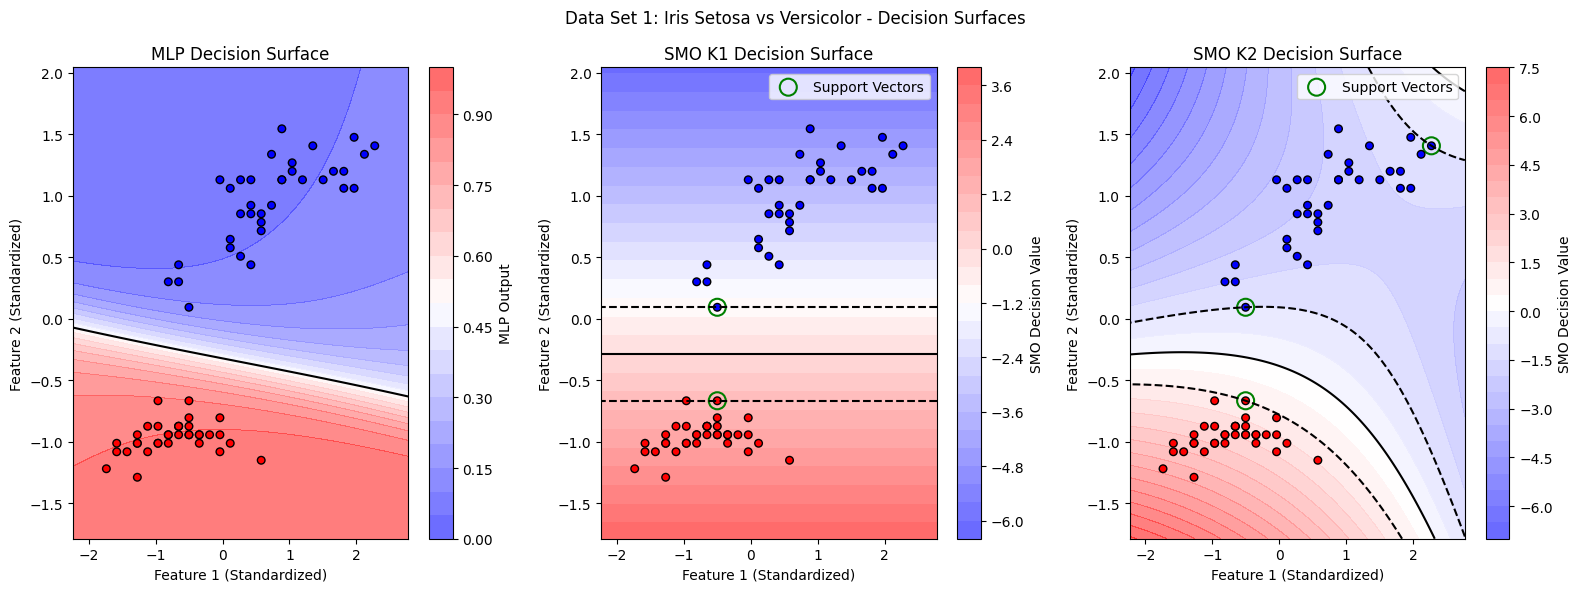

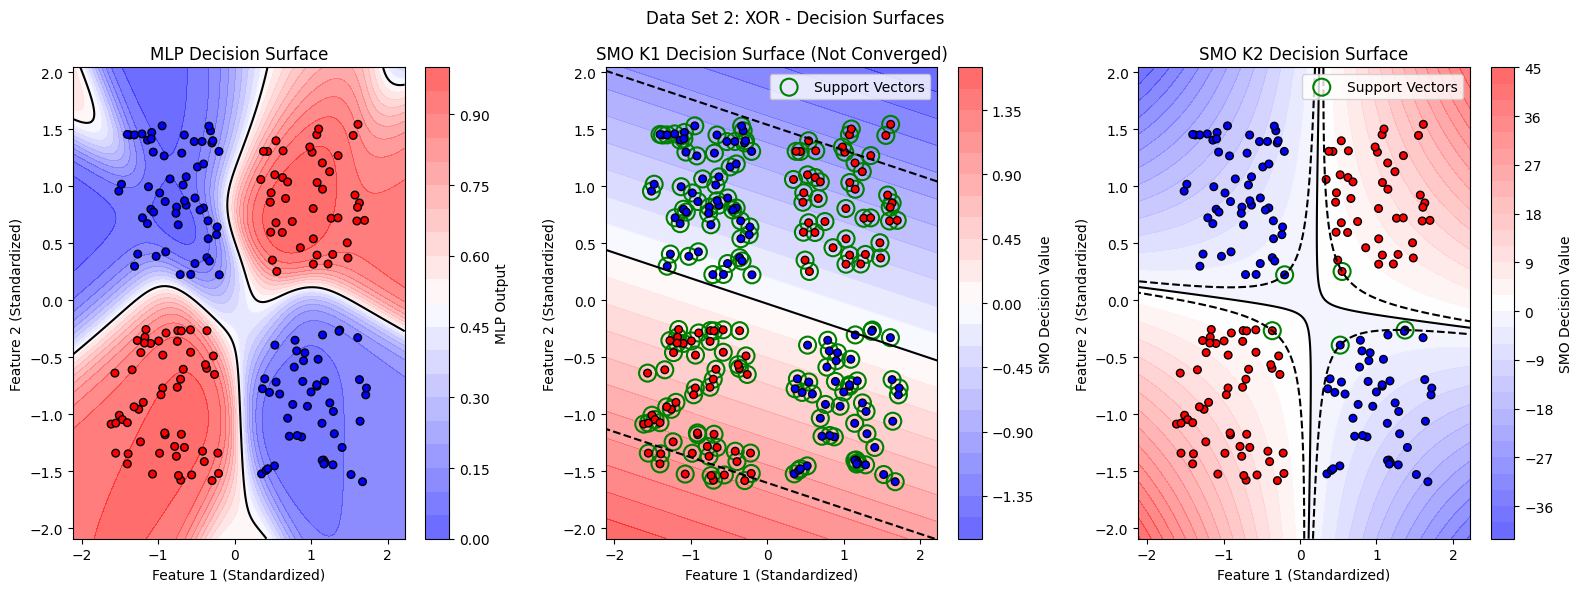

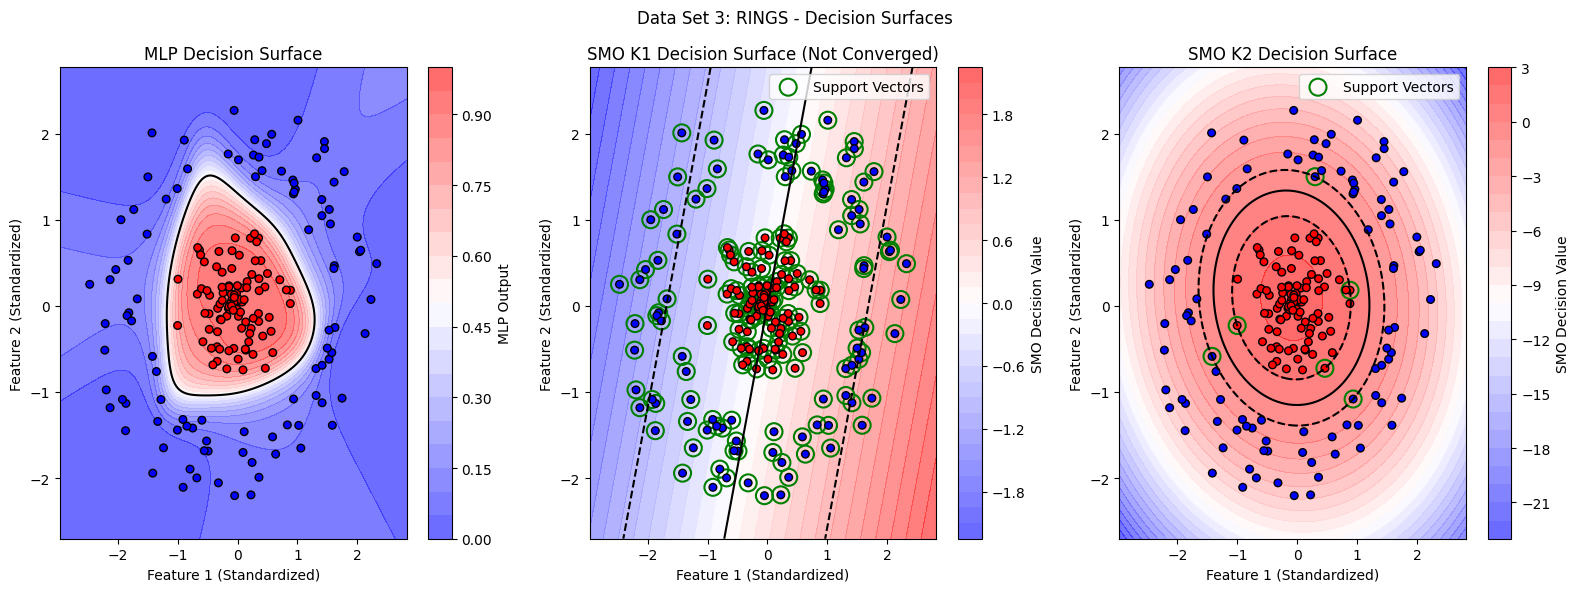

In [145]:
### a - Plot decision surfaces for data sets 1-3 - Joe
plotDecisionSurfaces(
    d1Xtr, d1ytr,
    d1W,
    d1k1alpha, d1k1bias,
    d1k2alpha, d1k2bias,
    "Data Set 1: Iris Setosa vs Versicolor - Decision Surfaces"
)
plotDecisionSurfaces(
    d2Xtr, d2ytr,
    d2W,
    d2k1alpha, d2k1bias,
    d2k2alpha, d2k2bias,
    "Data Set 2: XOR - Decision Surfaces",
    k1converged=False
)
plotDecisionSurfaces(
    d3Xtr, d3ytr,
    d3W,
    d3k1alpha, d3k1bias,
    d3k2alpha, d3k2bias,
    "Data Set 3: RINGS - Decision Surfaces",
    k1converged=False
)

### B - Comparison Table - Joe

In [146]:
### b - report summary table - Joe
# have to retrain the models for time reporting and mlp across 5 seeds
datasets = ["Iris, setosa vs. versicolor", "XOR", "Rings"]
Xtrs = [d1Xtr, d2Xtr, d3Xtr]
ytrs = [d1ytr, d2ytr, d3ytr]
Xtes = [d1Xte, d2Xte, d3Xte]
ytes = [d1yte, d2yte, d3yte]
kernels = [K1,K2]

# metrics to gather
converged = []
iterations = []
modelSizes = []
trainingTimes = []
testAccs = []
preds = []
smoLabels = []

# loop for smo
for i, data in enumerate(datasets):
    Xtr, ytr = Xtrs[i], ytrs[i]
    Xte, yte = Xtes[i], ytes[i]
    for j, kernel in enumerate(kernels):
        # training
        st = time.perf_counter()
        a, b, monitor = smo(
            Xtr, ytr, kernel=kernel,
            eps=EPS, tau=TAU,
            T=MAX_ITER, seed=RANDOM_SEED
        )
        trainingTimes.append(time.perf_counter() - st)

        # test preds
        if kernel==K1:
            Ktest = Xte @ Xtr.T
        else:
            Ktest = (Xte @ Xtr.T+1)**2
        vals = evalSMO(Ktest, ytr, a, b)
        ypred = np.where(vals >= 0, 1, -1)

        # report information
        preds.append(ypred)
        testAccs.append(np.mean(ypred==yte)*100) #percent based
        converged.append(monitor["converged"])
        iterations.append(monitor["iters"])
        modelSizes.append(np.sum(a > 0))
        smoLabels.append((data, "SMO K{}".format(j+1)))

# mlp metrics to gather
mlpConverged = []
mlpIterations = []
mlpModelSizes = []
mlpTrainingTimes = []
mlpTestAccs = []
mlpPreds = []
mlpLabels = []

# loop for mlp
for i, data in enumerate(datasets):
    Xtr, ytr = Xtrs[i], ytrs[i]
    Xte, yte = Xtes[i], ytes[i]

    for seed in range(5):
        #training
        st = time.perf_counter()
        W, monitor = mlp_train(
            Xtr, ytr, H=8,
            eta=0.3, alpha=0.3,
            epochs=1000, seed=seed
        )
        mlpTrainingTimes.append(time.perf_counter() - st)

        # test preds
        outputs, _ = forward(Xte, W)
        ypred = np.where(outputs.ravel() > 0.5, 1, -1)

        # report information
        mlpPreds.append(ypred)
        mlpTestAccs.append(np.mean(ypred == yte) * 100)
        # criterion is similar training misclassifications over last 50 epochs
        lastEpochs = np.array(monitor["miscs"][-50:])
        mlpConverged.append(np.ptp(lastEpochs) == 0) #https://numpy.org/doc/stable/reference/generated/numpy.ptp.html
        mlpIterations.append(1000)
        mlpModelSizes.append(4*8+1)# h is 8, 2 feature -H hidden - 1 output network size is 4H + 1
        mlpLabels.append((data, seed))


Converged, iteration number 74
Converged, iteration number 74
Converged, iteration number 286
Converged, iteration number 411


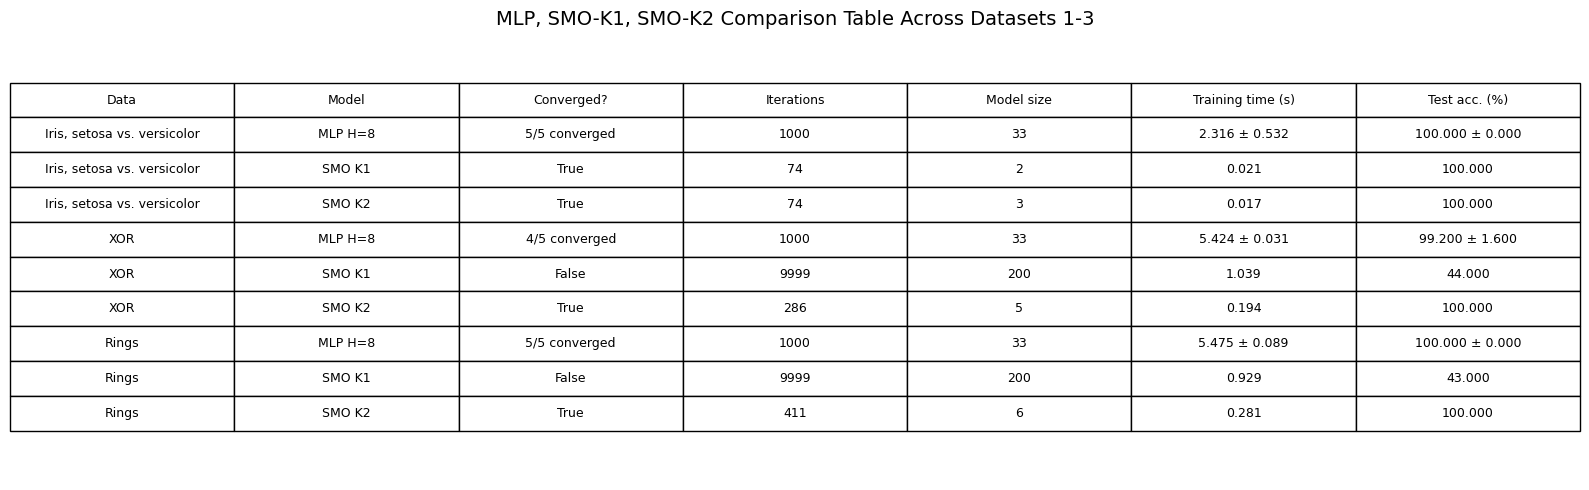

In [147]:
### output the data - Joe
rows = []
for i, data in enumerate(datasets):
    # MLP across 5 seeds
    st = i * 5
    end = st + 5
    accsMean = np.mean(mlpTestAccs[st:end])
    accsStd = np.std(mlpTestAccs[st:end])
    timesMean = np.mean(mlpTrainingTimes[st:end])
    timesSd = np.std(mlpTrainingTimes[st:end])
    numConverged = np.sum(mlpConverged[st:end])

    rows.append({
        "Data": data,
        "Model": "MLP H=8",
        "Converged?": "{}/5 converged".format(numConverged),
        "Iterations": mlpIterations[st],
        "Model size": mlpModelSizes[st],
        "Training time (s)": "{:.3f} ± {:.3f}".format(timesMean, timesSd),
        "Test acc. (%)": "{:.3f} ± {:.3f}".format(accsMean, accsStd)
    })

    # SMO two kernels
    for j in range(2):
        idx = i*2 + j

        rows.append({
            "Data": data,
            "Model": "SMO K{}".format(j+1),
            "Converged?": converged[idx],
            "Iterations": iterations[idx],
            "Model size": modelSizes[idx],
            "Training time (s)": "{:.3f}".format(trainingTimes[idx]),
            "Test acc. (%)": "{:.3f}".format(testAccs[idx])
        })

summaryDF = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(16, 5))
ax.axis("off")
table = ax.table(cellText=summaryDF.values,colLabels=summaryDF.columns,loc="center",cellLoc="center",)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.8)
ax.set_title("MLP, SMO-K1, SMO-K2 Comparison Table Across Datasets 1-3", fontsize=14)
plt.tight_layout()
plt.show()

In [148]:
### report confusion matrices - Joe
for i, data in enumerate(datasets):
    print("\n====DATA SET {} - {}====\n".format(i+1,data))
    # MLP across five seeds
    for seed in range(5):
        idx = i*5+seed
        print("MLP H=8 | Seed {}):".format(seed))
        print(confusion_matrix(ytes[i], mlpPreds[idx], labels=[-1, 1]))

    # SMO for 2 kernels
    for j in range(2):
        idx = i*2+j
        print("SMO K{}:".format(j+1))
        print(confusion_matrix(ytes[i], preds[idx], labels=[-1, 1]))



====DATA SET 1 - Iris, setosa vs. versicolor====

MLP H=8 | Seed 0):
[[15  0]
 [ 0 15]]
MLP H=8 | Seed 1):
[[15  0]
 [ 0 15]]
MLP H=8 | Seed 2):
[[15  0]
 [ 0 15]]
MLP H=8 | Seed 3):
[[15  0]
 [ 0 15]]
MLP H=8 | Seed 4):
[[15  0]
 [ 0 15]]
SMO K1:
[[15  0]
 [ 0 15]]
SMO K2:
[[15  0]
 [ 0 15]]

====DATA SET 2 - XOR====

MLP H=8 | Seed 0):
[[47  0]
 [ 0 53]]
MLP H=8 | Seed 1):
[[47  0]
 [ 0 53]]
MLP H=8 | Seed 2):
[[47  0]
 [ 0 53]]
MLP H=8 | Seed 3):
[[47  0]
 [ 0 53]]
MLP H=8 | Seed 4):
[[45  2]
 [ 2 51]]
SMO K1:
[[22 25]
 [31 22]]
SMO K2:
[[47  0]
 [ 0 53]]

====DATA SET 3 - Rings====

MLP H=8 | Seed 0):
[[50  0]
 [ 0 50]]
MLP H=8 | Seed 1):
[[50  0]
 [ 0 50]]
MLP H=8 | Seed 2):
[[50  0]
 [ 0 50]]
MLP H=8 | Seed 3):
[[50  0]
 [ 0 50]]
MLP H=8 | Seed 4):
[[50  0]
 [ 0 50]]
SMO K1:
[[22 28]
 [29 21]]
SMO K2:
[[50  0]
 [ 0 50]]


### C - Capacity on Data Set 3 - Joe

In [149]:
### C - Capacity on data set 3 - rings - Joe
Hs = [2, 3, 4, 16]
ds = [1, 2, 3, 4]

cap_Ws = []
for h in Hs:
    # MLP with H
    W, monitor = mlp_train(
        d3Xtr, d3ytr, h,
        epochs=1000,
        Xte=d3Xte, yte=d3yte
    )
    cap_Ws.append(W)

cap_alphas = []
cap_biases = []
cap_SMOmonitors = []
for d in ds:
    # Polynomial kernel of degree d
    Kernel = lambda X, Z, d=d: (X @ Z.T + 1)**d

    alpha, bias, monitor = smo(
        d3Xtr, d3ytr,
        kernel=Kernel, eps=EPS, tau=TAU,
        T=MAX_ITER, seed=RANDOM_SEED
    )

    cap_alphas.append(alpha)
    cap_biases.append(bias)
    cap_SMOmonitors.append(monitor)

Converged, iteration number 411
Converged, iteration number 423
Converged, iteration number 337


In [150]:
### Helper function to plot decision for MLP with different Hs - Joe
def plotMLPDecisionSurfaces(Xtr, ytr, Ws, Hs, title):
    # Reuse the mesh creation and other contour code from assignment 5
    fig, ax = plt.subplots(1, len(Hs), figsize=(15, 5))

    x1 = np.linspace(Xtr[:,0].min()-0.5, Xtr[:,0].max()+0.5, 200)
    x2 = np.linspace(Xtr[:,1].min()-0.5, Xtr[:,1].max()+0.5, 200)
    xx, yy = np.meshgrid(x1, x2)
    grid = np.c_[xx.ravel(), yy.ravel()]

    cfs = []
    for i in range(len(Hs)):

        # MLP decision surface
        mlpOutputs, _ = forward(grid, Ws[i])
        mlpVals = mlpOutputs.reshape(xx.shape)

        cf = ax[i].contourf(
            xx, yy, mlpVals,
            levels=np.linspace(0, 1, 21),
            cmap="bwr", vmin=0, vmax=1,
            alpha=0.6
        )
        cfs.append(cf)

        ax[i].contour(
            xx, yy, mlpVals,
            levels=[0.5],
            colors="black"
        )

        ax[i].set_title("H = {} Decision Surface".format(Hs[i]))

        # Training data points
        ax[i].scatter(
            Xtr[:,0], Xtr[:,1],
            c=ytr, cmap="bwr",
            vmin=-1, vmax=1,
            edgecolors="black",
            s=30
        )

        ax[i].set_xlabel("Feature 1 (Standardized)")
        ax[i].set_ylabel("Feature 2 (Standardized)")
        ax[i].set_xlim(x1.min(), x1.max())
        ax[i].set_ylim(x2.min(), x2.max())
        ax[i].set_aspect("equal", adjustable="box")

    fig.suptitle(title)

    # Shared colorbar for all MLP panels
    fig.colorbar(
        cfs[0],
        ax=ax,
        label="MLP Output",
        shrink=0.8
    )

    plt.show()

In [151]:
### Helper function to plot decision surfaces for SMO with different Ds - Joe
def plotSMODecisionSurfaces(Xtr, ytr, alphas, biases, Ds, title):
    # Reuse the mesh creation and other contour code from assignment 5
    fig, ax = plt.subplots(1, len(Ds), figsize=(15, 5))

    x1 = np.linspace(Xtr[:,0].min()-0.5, Xtr[:,0].max()+0.5, 200)
    x2 = np.linspace(Xtr[:,1].min()-0.5, Xtr[:,1].max()+0.5, 200)
    xx, yy = np.meshgrid(x1, x2)
    grid = np.c_[xx.ravel(), yy.ravel()]

    for i in range(len(Ds)):
        d = Ds[i]

        # SMO Kd decision surface
        Kdgrid = (grid @ Xtr.T + 1)**d
        KdVals = evalSMO(
            Kdgrid, ytr, alphas[i], biases[i]
        ).reshape(xx.shape)

        cf = ax[i].contourf(
            xx, yy, KdVals,
            levels=30, cmap="bwr", alpha=0.6
        )
        ax[i].contour(
            xx, yy, KdVals,
            levels=[-1, 0, 1],
            colors="black",
            linestyles=["--", "-", "--"]
        )

        # Support vectors
        sv = alphas[i] > 0
        ax[i].scatter(
            Xtr[sv, 0], Xtr[sv, 1],
            s=150,
            facecolors="none",
            edgecolors="green",
            linewidths=1.5,
            label="Support Vectors"
        )

        # Training data points
        ax[i].scatter(
            Xtr[:, 0], Xtr[:, 1],
            c=ytr, cmap="bwr",
            vmin=-1, vmax=1,
            edgecolors="black",
            s=30
        )

        ax[i].set_title(f"Polynomial Degree d={d}")
        ax[i].set_xlabel("Feature 1 (Standardized)")
        ax[i].set_ylabel("Feature 2 (Standardized)")
        ax[i].set_xlim(x1.min(), x1.max())
        ax[i].set_ylim(x2.min(), x2.max())
        ax[i].set_aspect("equal", adjustable="box")

        # Label nonconvergent linear kernel
        if d == 1:
            ax[i].set_title("D=1 Not Converged")
        ax[i].legend()
        fig.colorbar(cf, ax=ax[i], label="SMO Decision Value")

    fig.suptitle(title)
    plt.show()

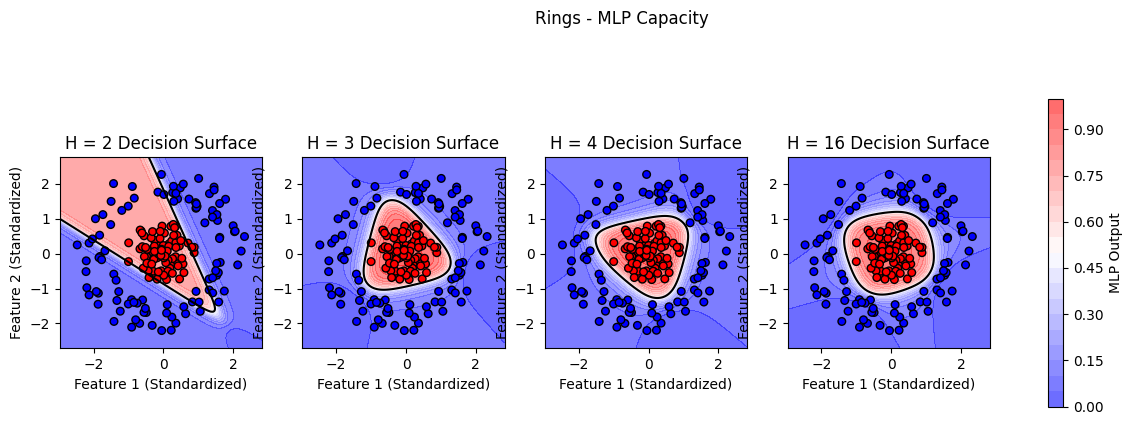

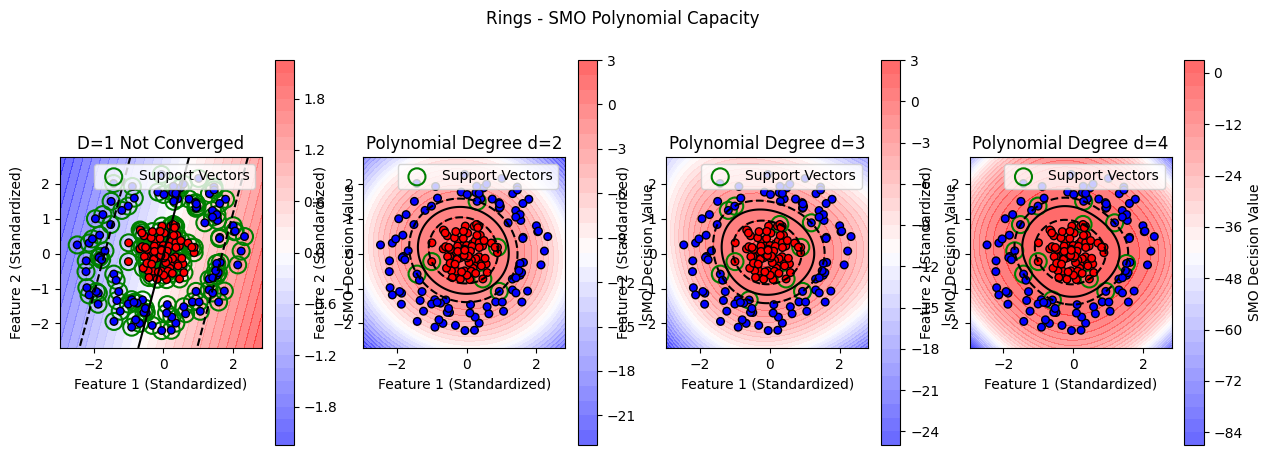

In [152]:
### Use the helper function to plot the decision surfaces
plotMLPDecisionSurfaces(d3Xtr, d3ytr,cap_Ws, Hs,"Rings - MLP Capacity")
plotSMODecisionSurfaces(d3Xtr, d3ytr,cap_alphas, cap_biases, ds,"Rings - SMO Polynomial Capacity")

In [153]:
### See via training acc what values separate the rings - JOe
# MLP training accs
for h, W in zip(Hs, cap_Ws):
    outputs, _ = forward(d3Xtr, W)
    pred = np.where(outputs.ravel()>0.5,1,-1)
    print("MLP H={} | {:.3f}".format(h,np.mean(pred==d3ytr)))

# SMO training accs
for d, a, b in zip(ds, cap_alphas, cap_biases):
    Ktrain = (d3Xtr @ d3Xtr.T + 1)**d
    vals = evalSMO(Ktrain, d3ytr, a, b)
    pred = np.where(vals >= 0, 1, -1)
    print("SMO d={} | {:.3f}".format(d,np.mean(pred == d3ytr)))

MLP H=2 | 0.895
MLP H=3 | 1.000
MLP H=4 | 1.000
MLP H=16 | 1.000
SMO d=1 | 0.465
SMO d=2 | 1.000
SMO d=3 | 1.000
SMO d=4 | 1.000


### D - Look inside the models on data sets 2 and 3 - Joe

In [154]:
### D - Look inside the models on data sets 2&3
def plotMLPHiddenLines(Xtr, ytr, W, title):
    x1 = np.linspace(Xtr[:,0].min()-0.5,Xtr[:,0].max()+0.5, 200)
    x2 = np.linspace(Xtr[:,1].min()-0.5,Xtr[:,1].max()+0.5, 200)
    xx, yy = np.meshgrid(x1, x2)
    grid = np.c_[xx.ravel(), yy.ravel()]

    # MLP decision surface
    outputs, _ = forward(grid, W)
    vals = outputs.reshape(xx.shape)

    # reused code from earlier
    fig, ax = plt.subplots(figsize=(8, 6))
    cf = ax.contourf(
        xx, yy, vals,
        levels=np.linspace(0, 1, 21),
        cmap="bwr", vmin=0, vmax=1,
        alpha=0.6
    )
    ax.contour(
        xx, yy, vals,
        levels=[0.5],
        colors="black",
        linewidths=2.5
    )

    # Add Hidden unit lines
    H = W.Hidden_Weights.shape[1]
    for j in range(H):
        # bias+ w1*x1 + w2*x2= 0
        z = (
            W.Hidden_Weights[0,j] * xx +
            W.Hidden_Weights[1,j] * yy +
            W.Hidden_Bias[0,j]
        )
        ax.contour(
            xx, yy, z,
            levels=[0],
            colors=["green"],
            linestyles="--",
            linewidths=1,
        )

    # Training points
    ax.scatter(
        Xtr[:,0], Xtr[:,1],
        c=ytr, cmap="bwr",
        vmin=-1, vmax=1,
        edgecolors="black",
        s=30
    )

    ax.set_title(title)
    ax.set_xlabel("Feature 1 (Standardized)")
    ax.set_ylabel("Feature 2 (Standardized)")
    ax.set_xlim(x1.min(), x1.max())
    ax.set_ylim(x2.min(), x2.max())
    fig.colorbar(cf, ax=ax, label="MLP Output")
    plt.tight_layout()
    plt.show()


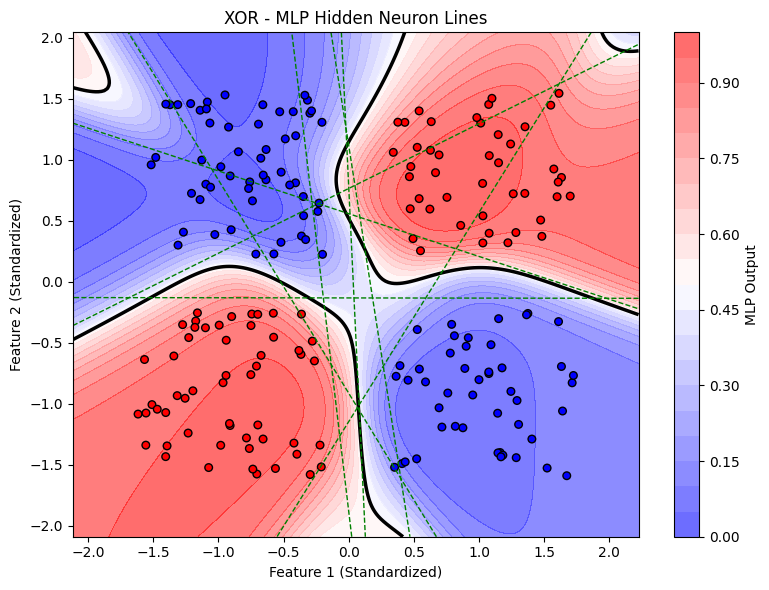

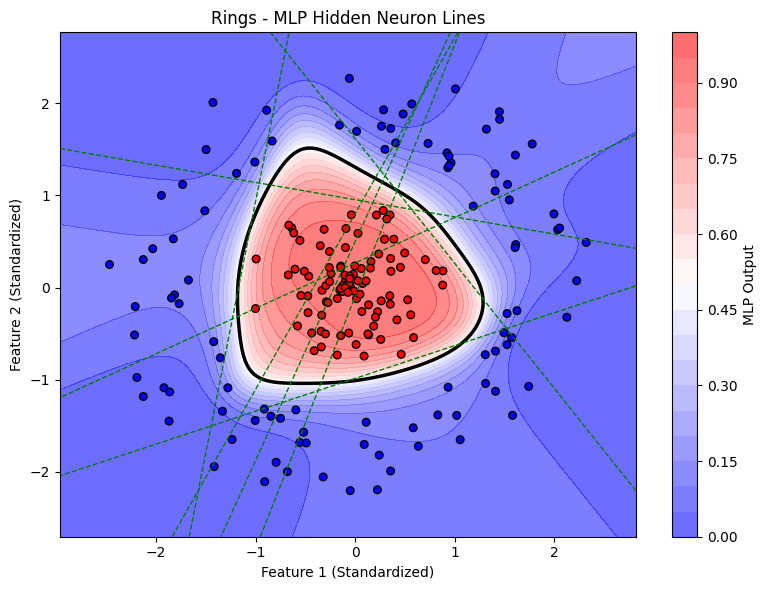

In [155]:
### plot the hidden lines- Joe
plotMLPHiddenLines(d2Xtr, d2ytr, d2W,"XOR - MLP Hidden Neuron Lines")
plotMLPHiddenLines(d3Xtr, d3ytr, d3W,"Rings - MLP Hidden Neuron Lines")

In [156]:
### helper to write SMo-K2 quadratic boundary using map from assignment 5
# https://en.wikipedia.org/wiki/Conic_section was a helpful source for me
def printSMOBoundary(Xtr, ytr, alphas, bias, title):
    ay = alphas * ytr

    a = np.sum(ay*Xtr[:,0]**2)
    b = 2*np.sum(ay*Xtr[:,0]*Xtr[:,1])
    c = np.sum(ay*Xtr[:,1]**2)
    d = 2 * np.sum(ay*Xtr[:,0])
    e = 2 * np.sum(ay*Xtr[:,1])
    f = np.sum(ay)+bias

    print("\n{}".format(title))
    print("{:+.5f}x1² {:+.5f}x1x2".format(a,b))
    print("{:+.5f}x2² {:+.5f}x1".format(c,d))
    print("{:+.5f}x2 {:+.5f} = 0".format(e,f))

    # discriminat
    disc = b**2 - 4*a*c
    print("Discriminant: {:.6f}".format(disc))

    # classify conic type
    if disc < -1e-8:
        print("Conic type: Ellipse type")
    elif disc > 1e-8:
        print("Conic type: Hyperbola type")
    else:
        print("Conic type: Parabola type")

    return a,b,c,d,e,f

In [157]:
### print outputs - Joe
d2Coeffs = printSMOBoundary(d2Xtr, d2ytr,d2k2alpha, d2k2bias,"Dataset 2 - XOR - SMO K2")
d3Coeffs = printSMOBoundary(d3Xtr, d3ytr,d3k2alpha, d3k2bias,"Dataset 2 - Rings - SMO K2")


Dataset 2 - XOR - SMO K2
+0.73370x1² +8.59383x1x2
-0.26394x2² +0.37007x1
-1.58750x2 -0.20195 = 0
Discriminant: 74.628539
Conic type: Hyperbola type

Dataset 2 - Rings - SMO K2
-1.41001x1² -0.20492x1x2
-1.54164x2² -0.25018x1
+0.26955x2 +2.35377 = 0
Discriminant: -8.652917
Conic type: Ellipse type


### E - Overlapping classes for dataset 4 - Joe

In [158]:
### another helper function to help plot
def plotMLPandSVC(Xtr, ytr, W, svc, title):
    # reused mesh code
    x1 = np.linspace(Xtr[:,0].min()-0.5, Xtr[:,0].max()+0.5, 200)
    x2 = np.linspace(Xtr[:,1].min()-0.5, Xtr[:,1].max()+0.5, 200)
    xx, yy = np.meshgrid(x1, x2)
    grid = np.c_[xx.ravel(), yy.ravel()]

    # functions
    mlpOutputs, _ = forward(grid, W)
    mlpVals = mlpOutputs.reshape(xx.shape)
    svcVals = svc.decision_function(grid).reshape(xx.shape)

    fig, ax = plt.subplots(1, 2, figsize=(15, 5))

    # contour plots
    cf0 = ax[0].contourf(
        xx, yy, mlpVals,
        levels=np.linspace(0, 1, 21),
        cmap="bwr", vmin=0, vmax=1,
        alpha=0.6
    )
    ax[0].contour(
        xx, yy, mlpVals,
        levels=[0.5], colors="black"
    )
    ax[0].set_title("MLP H = 4")
    cf1 = ax[1].contourf(
        xx, yy, svcVals,
        levels=30, cmap="bwr", alpha=0.6
    )
    ax[1].contour(
        xx, yy, svcVals,
        levels=[-1, 0, 1],
        colors="black",
        linestyles=["--", "-", "--"]
    )
    ax[1].set_title("Soft Margin SVC")

    # training points
    for a in ax:
        a.scatter(
            Xtr[:,0], Xtr[:,1],
            c=ytr, cmap="bwr",
            vmin=-1, vmax=1,
            edgecolors="black",
            s=35
        )
        a.set_xlabel("Feature 1 (Standardized)")
        a.set_ylabel("Feature 2 (Standardized)")
        a.set_xlim(x1.min(), x1.max())
        a.set_ylim(x2.min(), x2.max())

    fig.colorbar(cf0, ax=ax[0], label="MLP Output")
    fig.colorbar(cf1, ax=ax[1], label="SVC Decision Value")
    fig.suptitle(title)
    plt.show()

In [159]:
### E - Overlapping classes for dataset 4 - Joe
# train mlp 
d4WH4, d4monitorH4 = mlp_train(
    d4Xtr, d4ytr,4, epochs=1000
)

# train svc soft margin
d4SVC = SVC(
    kernel="poly",
    degree=2,
    gamma=1,
    coef0=1,
    C=1
)
d4SVC.fit(d4Xtr, d4ytr)

# preds
d4MLPOutputs, _ = forward(d4Xte, d4WH4)
d4MLPPreds = np.where(d4MLPOutputs.ravel()>0.5,1,-1)
d4SVCPreds = d4SVC.predict(d4Xte)

# report test accuracy and confusion matrices
print("MLP H = 4 Test Accuracy: {}".format(np.mean(d4MLPPreds==d4yte)))
print(confusion_matrix(d4yte, d4MLPPreds))
print("Soft Margin SVC Test Accuracy: {}".format(np.mean(d4SVCPreds==d4yte)))
print(confusion_matrix(d4yte, d4SVCPreds))

MLP H = 4 Test Accuracy: 0.9
[[10  0]
 [ 2  8]]
Soft Margin SVC Test Accuracy: 0.85
[[9 1]
 [2 8]]


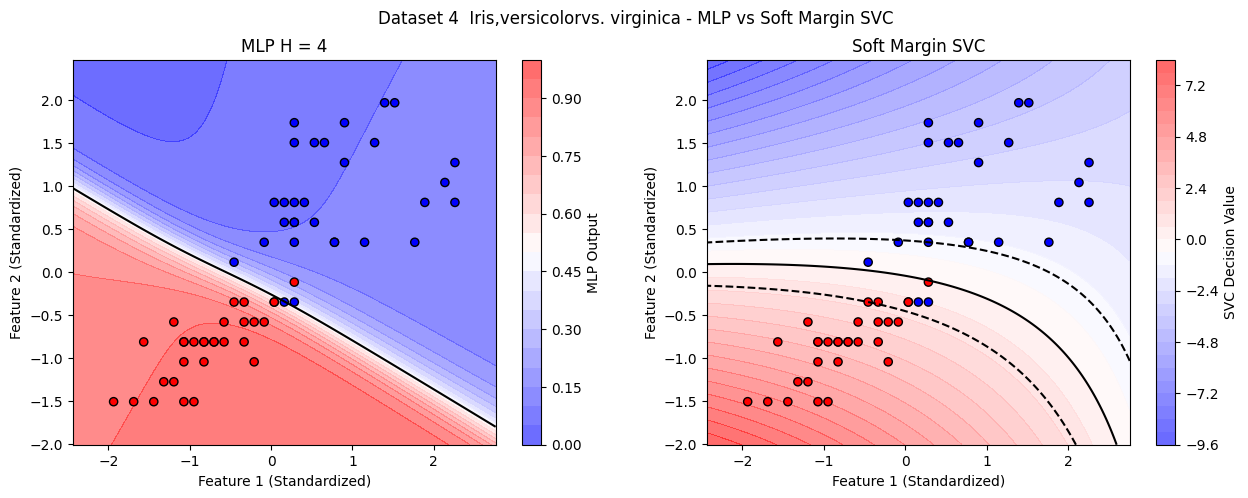

In [160]:
### plot the decision surfaces
plotMLPandSVC(d4Xtr, d4ytr,d4WH4, d4SVC,"Dataset 4  Iris,versicolorvs. virginica - MLP vs Soft Margin SVC")

MLP misclassified training indices: [11 42]
SVC misclassified training indices: [42 43]


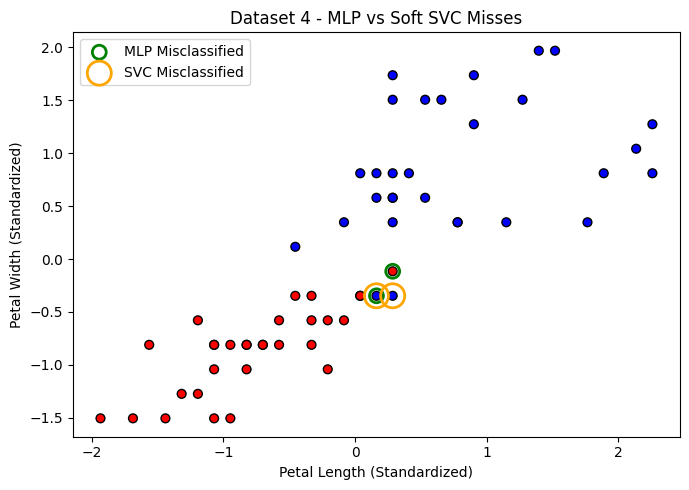

In [161]:
### compare training errs - Joe
# training outputs
mlpTrOutputs, _ = forward(d4Xtr, d4WH4)
mlpTrPreds = np.where(mlpTrOutputs.ravel() > 0.5, 1, -1)
svcTrPreds = d4SVC.predict(d4Xtr)

mlpWrong = np.where(mlpTrPreds != d4ytr)[0]
svcWrong = np.where(svcTrPreds != d4ytr)[0]

print("MLP misclassified training indices:", mlpWrong)
print("SVC misclassified training indices:", svcWrong)

fig, ax = plt.subplots(figsize=(7, 5))

# training points
ax.scatter(
    d4Xtr[:, 0], d4Xtr[:, 1],
    c=d4ytr, cmap="bwr",
    vmin=-1, vmax=1,
    edgecolors="black", s=40
)

# MLP miscs green
ax.scatter(
    d4Xtr[mlpWrong, 0], d4Xtr[mlpWrong, 1],
    s=100, facecolors="none",
    edgecolors="green", linewidths=2,
    label="MLP Misclassified"
)

# SVC miscs orange
ax.scatter(
    d4Xtr[svcWrong, 0], d4Xtr[svcWrong, 1],
    s=300, facecolors="none",
    edgecolors="orange", linewidths=2,
    label="SVC Misclassified"
)

ax.set_title("Dataset 4 - MLP vs Soft SVC Misses")
ax.set_xlabel("Petal Length (Standardized)")
ax.set_ylabel("Petal Width (Standardized)")
ax.legend()
plt.tight_layout()
plt.show()